# Network exploration

In [1]:
# All the imports
from pathlib import Path
import pandas as pd
import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import time, random
from scipy.stats import spearmanr

In [2]:
DATA = Path('../data')
edges = pd.read_csv(DATA / 'retweet_network_edges.csv',
                    dtype={'source_account_id': str, 'target_account_id': str,
                           'unresolved_target_tweet_id': str})

# edges with an unknown target account can't be network edges
known = edges.dropna(subset=['target_account_id'])
print(f'{len(edges):,} edge rows -> {len(known):,} with a known target')

# one weighted edge per account pair (weight = number of retweets)
pairs = (known.groupby(['source_account_id', 'target_account_id'], as_index=False)['retweet_count']
              .sum())
              
# Write to NCOL file
ncol_path = DATA / 'retweet_network.ncol'
pairs.to_csv(ncol_path, sep=' ', header=False, index=False)    # lines like: source target weight

1,531,425 edge rows -> 1,522,332 with a known target


In [3]:
g = ig.read(ncol_path, format='ncol', directed=True)
print(g.summary())
print('self-loops:', sum(g.is_loop()))

g2 = g.copy()
g2.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})

g_dir = g2 # keep for 2.7
g_und = g_dir.as_undirected(mode="collapse", combine_edges={"weight": "sum"})
print(g_und.summary())

IGRAPH DNW- 755988 1522332 -- 
+ attr: name (v), weight (e)
self-loops: 4038
IGRAPH UNW- 755988 1514676 -- 
+ attr: name (v), weight (e)


**Observations**

First graph is directed (D) for task 2.7 and the other is undirected (U) and named (N), with account IDs as the name attribute.

There are 4038 self loops, which mean that the original tweet is retweeted by the same user

4,038 edges were removed (the self loops) by simplify() (1,522,332 − 1,518,294). That is about 0.3% of the edges.

The typical account has only a couple of ties, and any hubs sit far above that average.

### Task 1.2 Summary of the network

In [4]:
order, size = g_und.vcount(), g_und.ecount()
deg = np.array(g_und.degree())
comps = g_und.connected_components()

summary = pd.Series({
    'order (vertices)': order,
    'size (edges)': size,
    'directed': g_und.is_directed(),
    'density': g_und.density(),
    'mean degree': 2 * size / order,                 # undirected: every edge adds to two degrees
    'max degree': deg.max(),
    'connected components': len(comps),
    'size of giant component': max(comps.sizes()),
    'total retweets (sum of weights)': int(sum(g_und.es['weight'])),
})
summary.to_frame('value')

,value
order (vertices),755988
size (edges),1514676
directed,False
density,0.000005
mean degree,4.007143
max degree,142209
connected components,10810
size of giant component,728820
total retweets (sum of weights),1828005


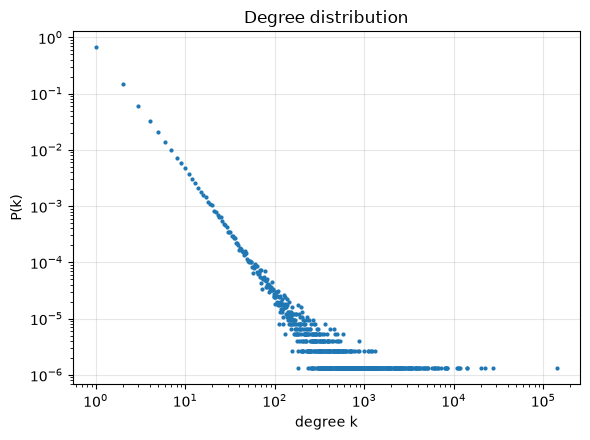

In [5]:
def pk(d):
    """P(degree = k) for k >= 1."""
    counts = np.bincount(d)
    k = np.nonzero(counts)[0]
    k = k[k > 0]
    return k, counts[k] / len(d)

fig, ax = plt.subplots(figsize=(6, 4.5))

k, p = pk(deg);   ax.loglog(k, p, '.', ms=4)

ax.set(xlabel='degree k', ylabel='P(k)', title='Degree distribution')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Observations**

The network is very sparse and hub-dominated, where the maximum degree is more than 35,000 times the mean. The degree distribution is heavy-tailed, close to a straight line on the log-log plot.

### Task 1.3 Different layouts of the network

In [6]:
strength = np.array(g_und.strength(weights='weight'))               # retweets sent + received
el = np.array(g_und.get_edgelist())

# how big is the core for different thresholds? aim is around roughly 2,000-20,000 vertices
for t in (5, 10, 20, 50, 100, 200):
    keep = strength >= t
    print(f'strength >= {t:>3}: {keep.sum():>8,} vertices, {(keep[el[:,0]] & keep[el[:,1]]).sum():>9,} edges')

strength >=   5:   88,044 vertices,   643,797 edges
strength >=  10:   38,713 vertices,   426,523 edges
strength >=  20:   16,893 vertices,   261,167 edges
strength >=  50:    5,648 vertices,   116,366 edges
strength >= 100:    2,592 vertices,    54,354 edges
strength >= 200:    1,210 vertices,    18,780 edges


In [7]:
MIN_STRENGTH = 50                                                  
H = g_dir.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
H = H.connected_components(mode='weak').giant()                    # drop small detached pieces
print(H.vcount(), 'vertices,', H.ecount(), 'edges')

H_dir = H # keep for 2.7
H_und = H_dir.as_undirected(mode="collapse", combine_edges={"weight": "sum"})
print(H_und.summary())

5424 vertices, 117269 edges
IGRAPH UNW- 5424 116365 -- 
+ attr: name (v), weight (e)


In [8]:
layout_names = ['random', 'circle', 'drl', 'lgl', 'fr']
if H_und.vcount() <= 3000:
    layout_names.append('kk')                                      # Kamada-Kawai is too slow for large graphs

layouts, times = {}, {}
for name in layout_names:
    random.seed(1)                                                 # same result on re-runs
    t0 = time.perf_counter()
    try:
        layouts[name] = H_und.layout(name)
    except Exception as e:
        print(name, 'failed:', e); continue
    times[name] = time.perf_counter() - t0
    print(f'{name:9s} {times[name]:7.1f} s')

random        0.0 s
circle        0.0 s
drl          97.9 s
lgl          25.4 s
fr            2.3 s


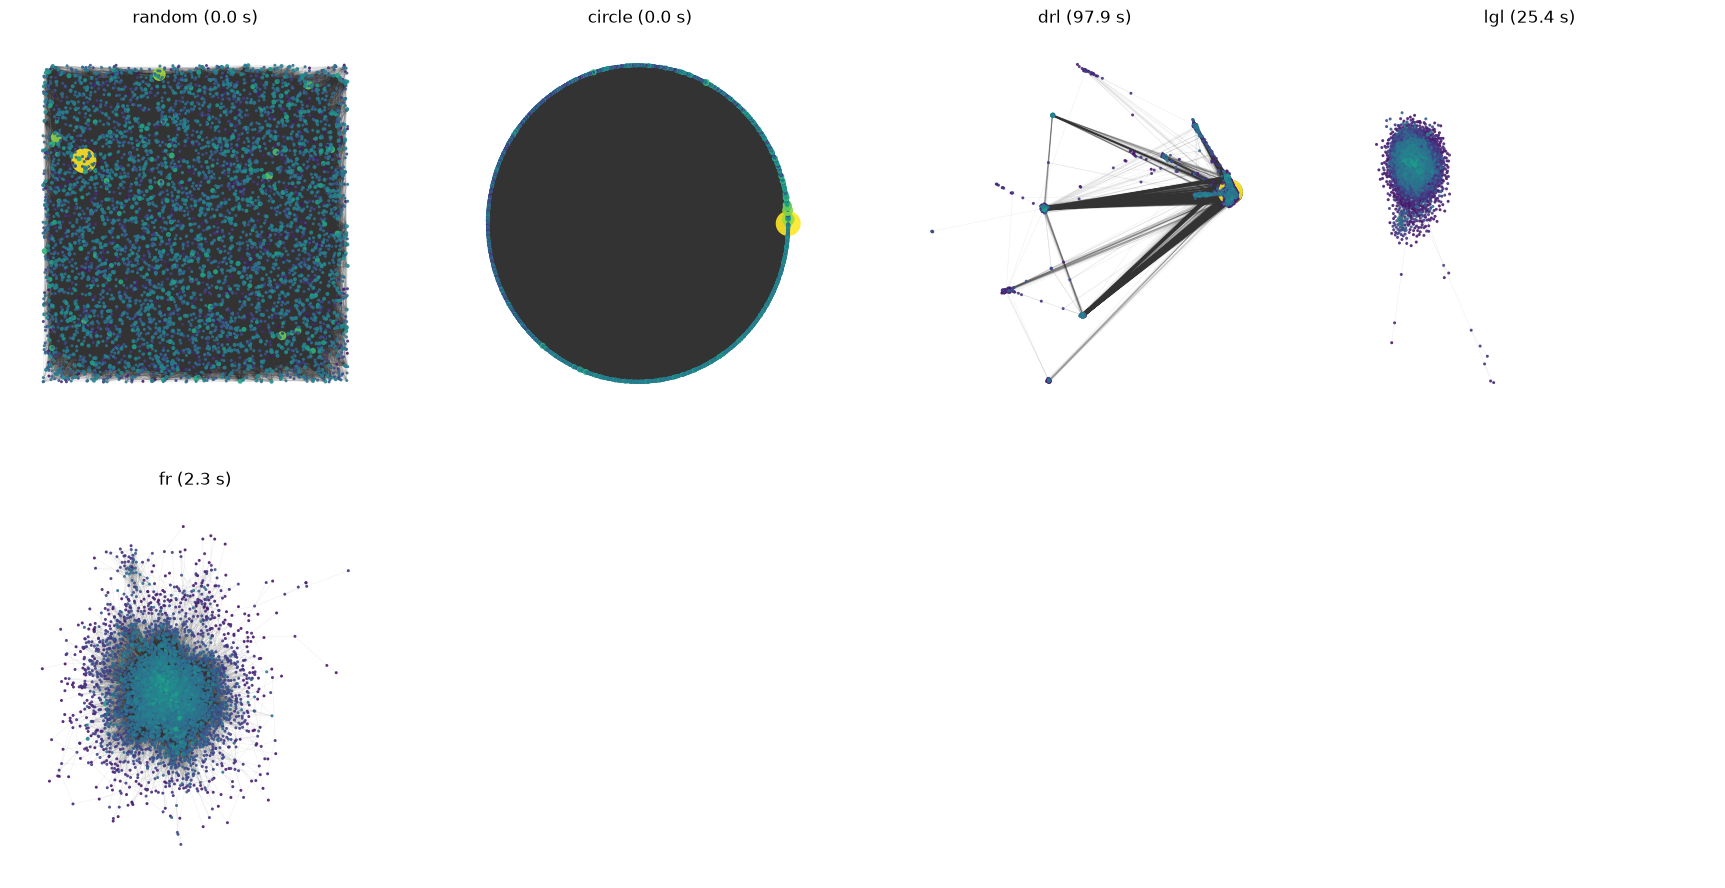

In [9]:
str_H = np.array(H_und.strength(weights='weight'))                    # retweets sent + received
size = 3 + 22 * np.sqrt(str_H / str_H.max())
shade = np.log1p(str_H) / np.log1p(str_H).max()
H_und.vs['color'] = [(*plt.cm.viridis(s)[:3], 0.9) for s in shade]    # bright = high strength (many retweets)
H_und.es['color'] = [(0.2, 0.2, 0.2, 0.08)] * H_und.ecount()              # very transparent edges

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for ax, name in zip(axes.ravel(), layouts):
    ig.plot(H_und, target=ax, layout=layouts[name], vertex_size=list(size),
            vertex_frame_width=0, vertex_label=None, edge_width=0.4)
    ax.set_title(f'{name} ({times[name]:.1f} s)')
for ax in axes.ravel()[len(layouts):]: ax.axis('off')
fig.savefig('layouts_compared.png', dpi=200, bbox_inches='tight')
plt.show()

**Observations**

The structure is hub-and-spoke, as the degree distribution suggested. Random and circle layouts only give the main hubs (in yellow), the rest is just a bunch of connections. DrL shows a few huge hubs with thick bundles of retweets from many low-degree accounts. FR and LGL show a dense core (many accounts that retweet and get retweeted) with a sparse periphery, plus a few distinct side clusters, probably separate communities or topics.

### Task 1.4 Hashtag stance in the retweet data

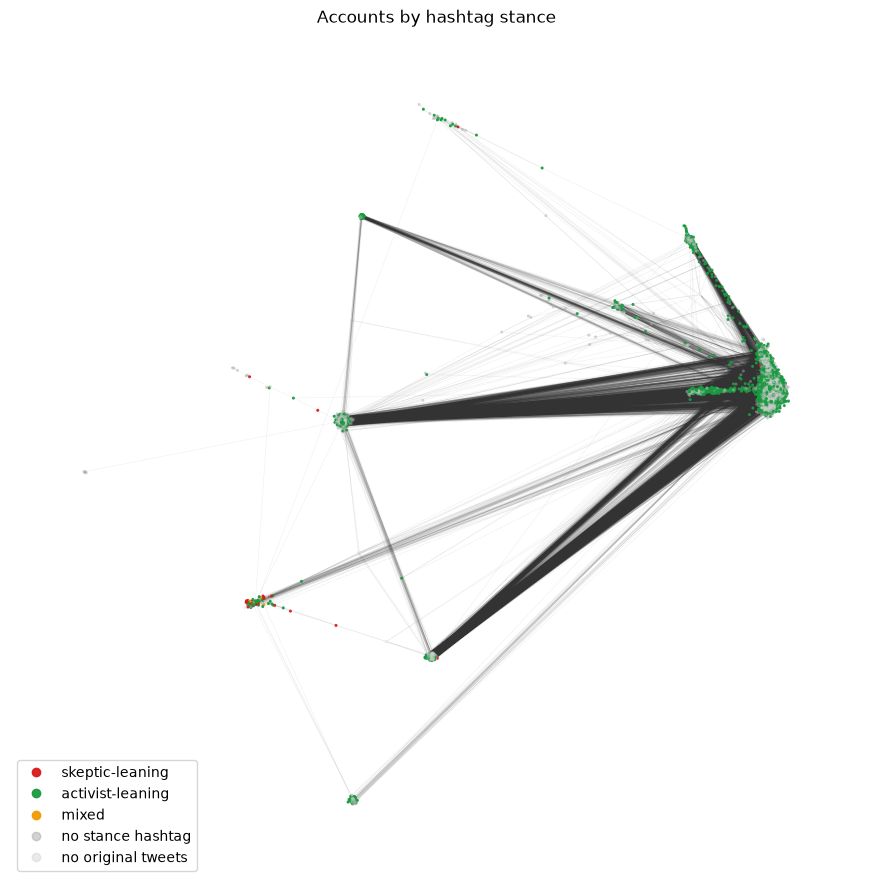

In [10]:
groups = pd.read_csv(DATA / 'account_groups.csv', dtype={'account_id': str}).set_index('account_id')
names = H_und.vs['name']

stance = groups['hashtag_stance'].reindex(names).fillna('no original tweets')
role   = groups['network_role'].reindex(names).fillna('not in retweet network')

stance_colors = {'skeptic-leaning':  (0.85, 0.10, 0.10, 0.95),
                 'activist-leaning': (0.10, 0.60, 0.25, 0.95),
                 'mixed':            (0.95, 0.60, 0.00, 0.95),
                 'no stance hashtag':(0.65, 0.65, 0.65, 0.50),
                 'no original tweets':(0.80, 0.80, 0.80, 0.40)}

def plot_categories(categories, palette, layout_name, title, fname=None):
    fig, ax = plt.subplots(figsize=(11, 11))
    ig.plot(H_und, target=ax, layout=layouts[layout_name],
            vertex_color=[palette[c] for c in categories],          # one colour per actor
            vertex_size=list(size), vertex_frame_width=0, vertex_label=None, edge_width=0.4)
    ax.set_title(title)
    ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=col, label=lab)
                       for lab, col in palette.items() if lab in set(categories)], loc='lower left')
    if fname: fig.savefig(fname, dpi=200, bbox_inches='tight')
    plt.show()

plot_categories(stance, stance_colors, 'drl', 'Accounts by hashtag stance', 'network_stance.png')   # use the layout you chose

In [11]:
# how many accounts per category in this plot?
print(stance.value_counts().to_frame('accounts').assign(share=lambda d: (d['accounts'] / d['accounts'].sum()).round(3)))

# who is linked to whom, by category (weighted by number of retweets)
# the graph is undirected, so every edge is counted in both directions; rows = group of one end, columns = group of the other
src, dst = (list(x) for x in zip(*H_und.get_edgelist()))
a = np.concatenate([stance.iloc[src].values, stance.iloc[dst].values])
b = np.concatenate([stance.iloc[dst].values, stance.iloc[src].values])
w = np.concatenate([H_und.es['weight'], H_und.es['weight']])
mix = pd.crosstab(a, b, values=w, aggfunc='sum').fillna(0)
display(mix.div(mix.sum(axis=1), axis=0).round(3))

# do like-minded accounts link to each other? (only for accounts that have a stance)
labelled = [i for i, s in enumerate(stance) if s in ('skeptic-leaning', 'activist-leaning', 'mixed')]
sub = H_und.induced_subgraph(labelled)
codes = pd.Categorical(stance.iloc[labelled]).codes.tolist()
print('nominal assortativity among labelled accounts:', sub.assortativity_nominal(codes, directed=False))

                    accounts  share
hashtag_stance                     
activist-leaning        3388  0.625
no original tweets      1570  0.289
no stance hashtag        434  0.080
skeptic-leaning           24  0.004
mixed                      8  0.001


col_0,activist-leaning,mixed,no original tweets,no stance hashtag,skeptic-leaning
row_0,,,,,
activist-leaning,0.601,0.000,0.369,0.029,0.000
mixed,0.764,0.000,0.127,0.045,0.064
no original tweets,0.882,0.000,0.074,0.043,0.001
no stance hashtag,0.555,0.000,0.345,0.099,0.001
skeptic-leaning,0.493,0.031,0.332,0.048,0.096


nominal assortativity among labelled accounts: 0.12851373175677835


**Observations**

Activist-leaning accounts dominate (60.1% of the accounts shown), while skeptic-leaning ones are very rare (24 accounts). Skeptics retweet each other far more compared to a random retweeting sample (9.6% vs 0.4% share), but most of their retweets still go to activists. Assortativity in the core (not for all of the actors) is weak (0.13), so stance separation - accounts more likely to retweet the same type of accounts - is modest and tentative. 

# PART 2: Micro-level Analysis

### Task 2.1 Degrees of the nodes

[[142209, '1006419421244678144'], [27243, '813286'], [22238, '878247600096509952']]


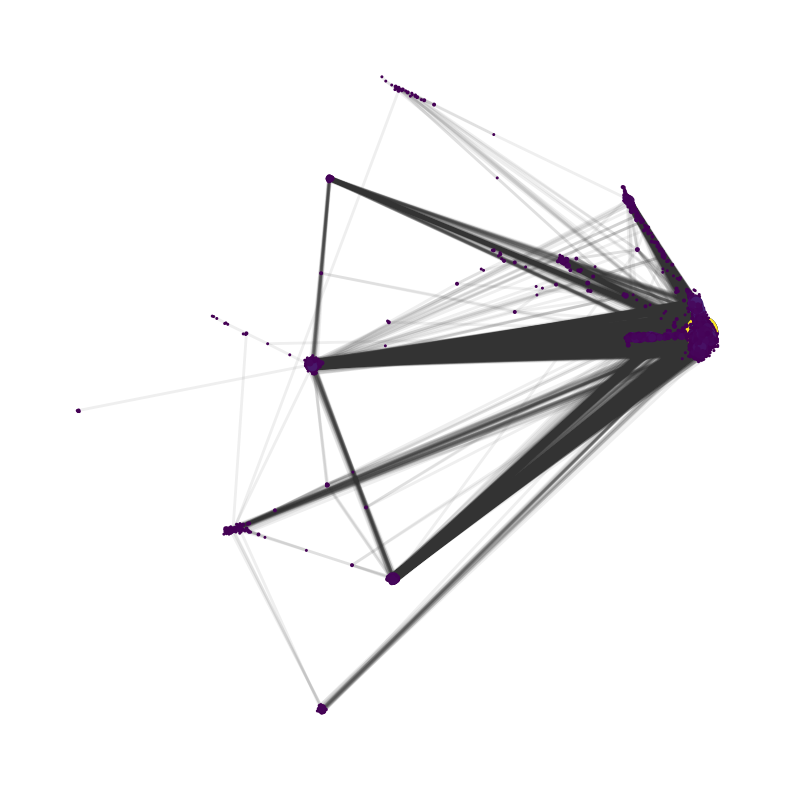

In [12]:
# Top-3 on the full (undirected) simplified graph
G = g_und
deg_G = G.degree()
act = G.vs["name"]
degrees = [ [ deg_G[i], act[i] ] for i in range(len(deg_G)) ]
degrees.sort(reverse = True)
print(degrees[0:3])

# Plot on the reduced graph that the layouts were computed on
deg_H = H_und.degree()
max_d = max(deg_H)

# Vertex size proportional to degree (sqrt so that the small nodes stay visible)
size_deg = [ 3 + 30 * (d / max_d) ** 0.5 for d in deg_H ]
# Vertex colour from degree
cmap = plt.get_cmap("viridis")
color_deg = [ cmap(d / max_d) for d in deg_H ]

fig, ax = plt.subplots(figsize=(10, 10))
ig.plot(H_und, target=ax, layout=layouts["drl"], vertex_size=size_deg,
        vertex_color=color_deg, vertex_label="", vertex_frame_width=0)
plt.show()

### Task 2.2 Betweenness functionality implementation

In [13]:
def calc_betweenness(graph, k):
  n = graph.vcount()
  nodes = list(range(n))
  seed = random.Random(42)
  source = seed.sample(nodes, k)
  target = seed.sample(nodes, k)

  paths = []
  
  for start in source:
    for end in target:
      if start != end:
        paths.append(graph.get_shortest_path(start, to=end, output = "vpath"))

  node_on_path = [0] * graph.vcount()
  for path in paths:
    for node in path[1: -1]:
      node_on_path[node] += 1

  scale = n * (n - 1) / (2 * len(paths))
  return [v * scale for v in node_on_path]

In [14]:
er = ig.Graph.Erdos_Renyi(n=H_und.vcount(), m=H_und.ecount(), directed=False)
k = 1000

exact_H = H_und.betweenness(directed = False)
exact_er = er.betweenness(directed = False)
approx_H = calc_betweenness(H_und, k)
approx_er = calc_betweenness(er, k)

print(spearmanr(approx_H, exact_H).correlation)
print(spearmanr(approx_er, exact_er).correlation)

top = 20
top_exact  = np.argsort(exact_H)[::-1][:top]     # vertex IDs, highest betweenness first
top_approx = np.argsort(approx_H)[::-1][:top]

print("overlap (ours and igraph on network H) in top", top, ":", len(set(top_exact) & set(top_approx)))

for rank, (e, a) in enumerate(zip(top_exact, top_approx), 1):
    print(rank, "| exact:", H_und.vs[e]["name"], round(exact_H[e]),
                "| approx:", H_und.vs[a]["name"], round(approx_H[a]))

0.7203719637935873
0.3928946542569038
overlap (ours and igraph on network H) in top 20 : 13
1 | exact: 1006419421244678144 4097091 | approx: 1006419421244678144 10739710
2 | exact: 1174664712291794944 1284779 | approx: 1174664712291794944 886526
3 | exact: 15088481 1003828 | approx: 14159148 622516
4 | exact: 14266598 874416 | approx: 14266598 412873
5 | exact: 21786618 421568 | approx: 15088481 370818
6 | exact: 2518143973 388045 | approx: 2712674750 224574
7 | exact: 3459051 356492 | approx: 2518143973 174325
8 | exact: 14159148 273342 | approx: 26657119 166808
9 | exact: 159955958 179379 | approx: 159955958 145376
10 | exact: 1075123146641039363 179090 | approx: 35692915 138625
11 | exact: 811229675758505984 173255 | approx: 18080108 135918
12 | exact: 35692915 163065 | approx: 28690225 134403
13 | exact: 2712674750 160467 | approx: 17463923 133344
14 | exact: 17463923 140457 | approx: 2923724679 102409
15 | exact: 241122100 128205 | approx: 811229675758505984 90024
16 | exact: 1067

***Observations***

Our function of betweenness takes a sample from the nodes and calculates the betweenness on them. Therefore for smaller smaple size (k) values, the betweenness measures differ more. The more nodes are sampled the higher the overlap of betweenness measures climbs (0.49 → 0.62 → 0.67 → 0.75 on H, and 0.28 → 0.37 → 0.45 → 0.52 on ER for k = 200, 400, 600, 1000). However they climb more for the H network than for the random ER one. It can also be seen that the nodes with the highest betweenness align between our implementation and the iGraph one. The validation on the ER network performs worse because the betweenness will be similar for all the nodes, therefore there is little ranking to recover and the sampling will not highlight that as well.

### Task 2.3 Top 10 actors for degree and betweenness

--- Retweet network (core) ---
Top degree:      [('1006419421244678144', 2927), ('15088481', 1817), ('14266598', 1714), ('21786618', 1278), ('2518143973', 1198), ('3459051', 1111), ('159955958', 812), ('1075123146641039363', 799), ('241122100', 668), ('14159148', 660)]
Top betweenness: [('1006419421244678144', 4097090), ('1174664712291794944', 1284778), ('15088481', 1003828), ('14266598', 874416), ('21786618', 421567), ('2518143973', 388044), ('3459051', 356491), ('14159148', 273342), ('159955958', 179379), ('1075123146641039363', 179090)]
overlap: 9 of 10
--- ER graph ---
Top degree:      [(5286, 68), (802, 68), (4140, 66), (1321, 65), (2527, 64), (3143, 64), (1000, 63), (880, 63), (3095, 63), (4644, 63)]
Top betweenness: [(5286, 11254), (802, 11252), (4140, 10415), (1321, 10223), (2527, 9935), (3143, 9933), (3095, 9734), (4644, 9721), (1000, 9688), (1421, 9466)]
overlap: 9 of 10


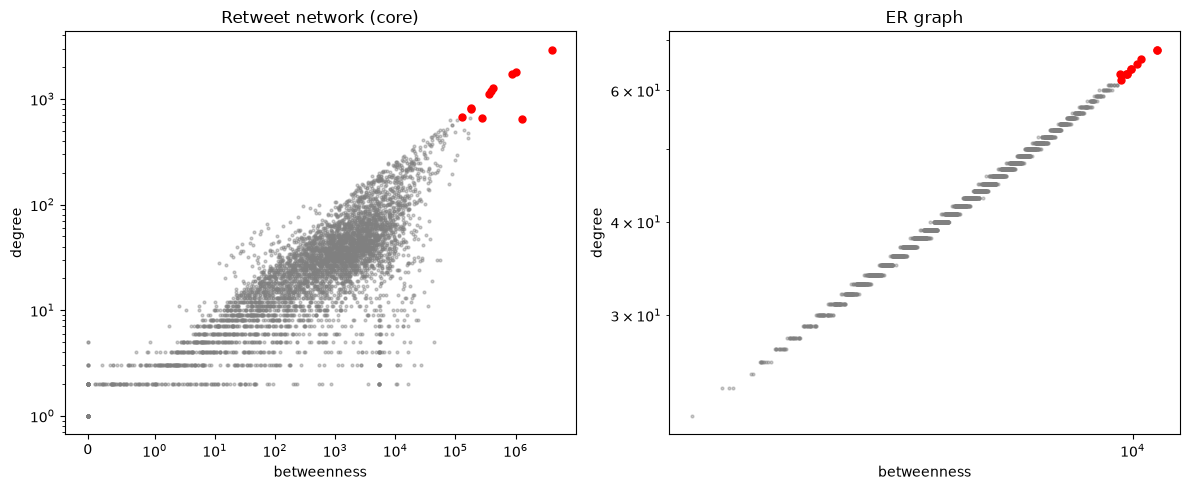

In [15]:
def top_and_plot(graph, bet, title, ax, top=10):
    deg = np.array(graph.degree())
    bet = np.array(bet)
    ids = graph.vs["name"] if "name" in graph.vs.attributes() else list(range(graph.vcount()))

    top_deg = np.argsort(deg)[::-1][:top]
    top_bet = np.argsort(bet)[::-1][:top]

    print(f"--- {title} ---")
    print("Top degree:     ", [(ids[i], int(deg[i])) for i in top_deg])
    print("Top betweenness:", [(ids[i], int(bet[i])) for i in top_bet])
    print("overlap:", len(set(top_deg) & set(top_bet)), "of", top)

    ax.scatter(bet, deg, s=4, alpha=0.4, color="grey")
    both = list(set(top_deg) | set(top_bet))                 # highlight the top-10 of either measure
    ax.scatter(bet[both], deg[both], s=25, color="red")
    ax.set_xscale("symlog", linthresh=1)                     # symlog because many nodes have betweenness 0
    ax.set_yscale("log")
    ax.set_xlabel("betweenness"); ax.set_ylabel("degree"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_and_plot(H_und, exact_H,  "Retweet network (core)", axes[0])      # exact values from 2.2
top_and_plot(er,    exact_er, "ER graph", axes[1])
plt.tight_layout()
plt.savefig("betweenness_vs_degree.png", dpi=150)
plt.show()

***Observations***

9 out of 10 highest degree and highest betweenness actors overlap for both the ER and the H network. Therefore they are mostly complementary with some outliers.

Betweenness and degree are positively related, with the hubs in the top right, as expected. For a given degree, betweenness varies by orders of magnitude, and accounts far to the right of their degree are brokers that connect otherwise separate groups, which degree alone does not reveal. Many accounts with degree > 0 have betweenness 0 (they only retweet or are only retweeted). The ER graph shows a tight cloud with no outliers.

### Task 2.4 Missing description of the task ://

### Task 2.5 Top-k actors

***Observations***

### Task 2.6 Actors with low/high clustering coefficient

***Observations***

### Task 2.7 Strength, hub and authority scores directed and weighted

In [16]:
# Already directed networks
g_dir, H_dir

(<igraph.Graph at 0x25551a49350>, <igraph.Graph at 0x2550df76250>)

***Observations***

# Part 3: Processes on networks

### Task 3.1 Netowrks largest component

***Observations***

### Task 3.2 Network token passing simulation

### Task 3.3 Information difusion process simulation

### Task 3.4 Opinion difusion process simulation